<a href="https://www.kaggle.com/code/lourdesgarcagarfias/3c-ritmo-preparacion-datos?scriptVersionId=374134786" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Notebook 03 · Preparación de los datos (limpiar, transformar y normalizar)

** Módulo de ritmos (detección de fibrilación auricular)**

Este notebook toma las señales crudas de dos bases y las convierte en una sola tabla limpia, lista para el notebook 04 (división) y para entrenar.

```
Señal cruda (.mat / .dat)
   │  TRANSFORMAR: todo a 360 Hz
   │  LIMPIAR: filtro 0.5–40 Hz, ignorar el 1er segundo, detector R mejorado, quitar R–R imposibles
   │  TRANSFORMAR: cortar en ventanas de 30 s → 9 medidas por ventana
   │  NORMALIZAR (por señal): medidas relativas, que no dependen del aparato
   ▼
datos/medidas_ritmo.csv   (una fila por ventana)
```

| Base | Para qué | Qué tiene |
|---|---|---|
| **CinC 2017** | Entrenar y probar | 8,528 registros cortos de AliveCor (300 Hz), etiqueta por registro: N, A, O, ~ |
| **MIT-BIH AF** | Entrenar y probar **separando pacientes** | 23 pacientes con ~10 h cada uno (250 Hz), con tramos de ritmo anotados |

> **Los requisitos del modelo:** el modelo final correrá en un **Arduino, en tiempo real**. Por eso todo lo que se hace aquí debe poder hacerse en el Arduino: filtros **causales** (solo usan el pasado), cuentas sencillas y una frecuencia fija de 360 Hz.

Este notebook **no depende de `ecg_comun.py`**: todo el código de preparación está aquí, a la vista.

In [1]:
%pip install -q wfdb numpy pandas scipy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 1. Inicialización y ubicación de los datos


In [2]:
from fractions import Fraction
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from IPython.display import display
from scipy.io import loadmat
from scipy.signal import butter, find_peaks, resample_poly, sosfilt

plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True

EN_KAGGLE = Path("/kaggle/input").exists()
SALIDA = Path("/kaggle/working/datos") if EN_KAGGLE else Path("datos")
SALIDA.mkdir(parents=True, exist_ok=True)
ENTRADA = Path("/kaggle/input") if EN_KAGGLE else Path("datos")

# --- CinC 2017: buscar la carpeta que tiene las etiquetas
ref = next(ENTRADA.rglob("REFERENCE-v3.csv"), None) or next(ENTRADA.rglob("REFERENCE.csv"), None)
if ref is None:
    raise FileNotFoundError("No encontré CinC 2017. Descárgalo como en el notebook anterior (curl) dentro de datos/cinc2017")
CARPETA_CINC = ref.parent
print("CinC 2017 en:", CARPETA_CINC, "· etiquetas:", ref.name)

# --- MIT-BIH AF: usar la que ya exista o descargar SOLO lo que falte (con reintentos)
import time
REGISTROS_AFDB = ["04015", "04043", "04048", "04126", "04746", "04908", "04936", "05091", "05121", "05261",
                  "06426", "06453", "06995", "07162", "07859", "07879", "07910", "08215", "08219", "08378",
                  "08405", "08434", "08455"]          # los 23 con señal (00735 y 03665 no traen señal)

def afdb_incompletos(carpeta):
    # Devuelve los registros a los que les falta un archivo o cuya señal (.dat) quedó a medias
    faltan = []
    for r in REGISTROS_AFDB:
        dat = carpeta / f"{r}.dat"
        if not all((carpeta / f"{r}.{ext}").exists() for ext in ("hea", "dat", "atr")):
            faltan.append(r)
            continue
        try:
            cab = wfdb.rdheader(str(carpeta / r))
            if dat.stat().st_size < int(np.ceil(cab.sig_len * cab.n_sig * 1.5)):   # formato 212 = 1.5 bytes/muestra
                faltan.append(r)
        except Exception:
            faltan.append(r)
    return faltan

hea = next(ENTRADA.rglob("04015.hea"), None)
CARPETA_AFDB = hea.parent if hea else SALIDA / "afdb"
faltan = afdb_incompletos(CARPETA_AFDB)
if faltan:
    print(f"Faltan {len(faltan)} de {len(REGISTROS_AFDB)} registros de MIT-BIH AF. Descargando...")
    for r in faltan:
        for intento in range(1, 6):
            try:
                wfdb.dl_database("afdb", str(CARPETA_AFDB), records=[r])   # si un archivo ya está completo, no lo repite
                break
            except Exception as e:
                print(f"  {r}: PhysioNet falló ({type(e).__name__}). Reintento {intento}/5 en 30 s...")
                time.sleep(30)
    faltan = afdb_incompletos(CARPETA_AFDB)
    if faltan:
        raise RuntimeError(f"Aún faltan {faltan}. PhysioNet está fallando: vuelve a correr esta celda más tarde.")
print("✓ MIT-BIH AF completa (23 registros)")
print("MIT-BIH AF en:", CARPETA_AFDB)

CinC 2017 en: /kaggle/input/datasets/lourdesgarcagarfias/cinc2017-proyecto7/cinc2017-proyecto7 · etiquetas: REFERENCE-v3.csv
Faltan 23 de 23 registros de MIT-BIH AF. Descargando...
Generating record list for: 04015
Generating list of all files for: 04015
Created local base download directory: /kaggle/working/datos/afdb
Finished downloading files
Generating record list for: 04043
Generating list of all files for: 04043
Finished downloading files
Generating record list for: 04048
Generating list of all files for: 04048
Finished downloading files
Generating record list for: 04126
Generating list of all files for: 04126
Finished downloading files
Generating record list for: 04746
Generating list of all files for: 04746
Finished downloading files
Generating record list for: 04908
Generating list of all files for: 04908
Finished downloading files
Generating record list for: 04936
Generating list of all files for: 04936
Finished downloading files
Generating record list for: 05091
Generating l

## 2. Decisiones de preparación

Todas juntas para poder justificarlas (y cambiarlas) en un solo lugar.

| Decisión | Valor | Por qué |
|---|---|---|
| Frecuencia común | 360 Hz | La de MIT-BIH Arrhythmia y la que usará el Arduino |
| Filtro | 0.5–40 Hz, causal | Quita la deriva de línea base y el ruido rápido; causal = posible en tiempo real |
| Ignorar el inicio | 1 s | El filtro causal produce un brinco falso al arrancar (lo vimos en A00004 y A00008) |
| Ventana | 30 s | La duración de casi todos los registros de CinC 2017 |
| R–R válido | 0.25–2.5 s | Fuera de ese rango es casi seguro un error del detector |
| Mínimo de latidos | 8 | Petrėnas et al. (2015) detectan FA con ventanas de 8 latidos |
| Pureza de la ventana (MIT-BIH AF) | ≥ 90 % | Una ventana solo se usa si al menos el 90 % de su tiempo tiene el mismo ritmo, para que la etiqueta sea clara |
| Ritmos de MIT-BIH AF → clases de CinC | AFIB → A · N → N · AFL, J → O | Así las dos bases usan las mismas 4 clases |

In [3]:
FS = 360
FILTRO_HZ = (0.5, 40.0)
IGNORAR_INICIO_S = 1.0
VENTANA_S = 30
RR_MIN, RR_MAX = 0.25, 2.5
MIN_LATIDOS = 8
PUREZA_MIN = 0.90
MAPEO_AFDB = {"N": "N", "AFIB": "A", "AFL": "O", "J": "O"}

---
# PARTE A · Las funciones de limpieza y transformación

## A.1 Leer las señales
- **CinC 2017**, lo que hace es guardar los números sin decimales en un `.mat` (en "milésimas de mV"): se dividen entre la ganancia que dice el `.hea` (1000) para pasarlos a **mV**.
- **MIT-BIH AF** se lee con `wfdb`, que ya entrega mV. Sus ritmos vienen como **notas** en el archivo `.atr` (por ejemplo `(AFIB` = "desde aquí empieza FA").

In [4]:
def leer_cinc(ruta_mat):
    # Devuelve (señal en mV, frecuencia)
    crudo = loadmat(ruta_mat)["val"][0].astype(np.float64)
    ganancia, fs = 1000.0, 300
    lineas = Path(ruta_mat).with_suffix(".hea").read_text().split("\n")
    fs = int(float(lineas[0].split()[2]))
    try:
        ganancia = float(lineas[1].split()[2].split("/")[0].split("(")[0])
    except (IndexError, ValueError):
        pass
    return crudo / ganancia, fs


def leer_afdb(nombre):
    # Devuelve (señal en mV del canal 1, frecuencia, lista de tramos (inicio_s, fin_s, ritmo))
    ruta = str(CARPETA_AFDB / nombre)
    reg = wfdb.rdrecord(ruta, channels=[0])
    x, fs = reg.p_signal[:, 0].astype(np.float64), int(reg.fs)
    ann = wfdb.rdann(ruta, "atr")
    cambios = [(s / fs, t.strip("\x00").strip().lstrip("("))
               for s, t in zip(ann.sample, ann.aux_note) if t and t.strip("\x00").strip().startswith("(")]
    dur = len(x) / fs
    tramos = [(ini, cambios[i + 1][0] if i + 1 < len(cambios) else dur, rit) for i, (ini, rit) in enumerate(cambios)]
    return x, fs, tramos


def registros_afdb():
    # Solo los registros que sí traen señal (00735 y 03665 no la tienen)
    nombres = []
    for h in sorted(CARPETA_AFDB.glob("*.hea")):
        cab = wfdb.rdheader(str(h.with_suffix("")))
        if cab.n_sig and cab.file_name and all((CARPETA_AFDB / f).exists() for f in cab.file_name):
            nombres.append(h.stem)
    return nombres

## A.2 Transformar a 360 Hz y limpiar con el filtro

- `remuestrear`: cambia el número de muestras por segundo **sin cambiar la forma** de la onda (300 → 360, o 250 → 360).
- `filtrar`: pasabanda **causal** de 0.5 a 40 Hz. Quita la ondulación lenta (respiración, movimiento) y los "temblorcitos" rápidos (músculo, red eléctrica).

In [5]:
def remuestrear(x, fs_origen, fs_destino=FS):
    if fs_origen == fs_destino:
        return x
    f = Fraction(fs_destino, fs_origen).limit_denominator(1000)
    return resample_poly(x, f.numerator, f.denominator)


def filtrar(x, fs=FS):
    sos = butter(2, FILTRO_HZ, btype="bandpass", fs=fs, output="sos")
    return sosfilt(sos, x)

## A.3 Detector de picos R **mejorado**

Es el mismo Pan–Tompkins de antes, con **tres mejoras** que salieron del análisis de errores del punto 2:

| Problema que vimos | Mejora |
|---|---|
| Detección falsa en los primeros 0.2 s (A00004, A00008) | **Ignora el primer segundo** |
| Un artefacto al inicio dejaba el umbral altísimo (A00054) | El umbral inicial usa la **mediana** de los máximos de cada segundo (los primeros 8 s), no el máximo de todo: un artefacto de unos segundos ya no lo engaña |
| Después de un artefacto ya no veía los latidos pequeños | Si pasan **más de 2 s sin latido**, el umbral **baja a la mitad** cada segundo hasta volver a encontrarlos |

Probado con un registro real de MIT-BIH (el 100), con un artefacto artificial al inicio: el detector anterior encontró 4 de 36 latidos y este encuentra 32 de 36. Sin artefacto, los dos encuentran el 99.96 %.

In [6]:
def detectar_picos_r(x, fs=FS):
    x = np.asarray(x, dtype=np.float64)
    # 1-4. Resaltar el QRS: pasabanda 5-15 Hz, derivada, cuadrado, ventana móvil de 150 ms
    banda = sosfilt(butter(2, [5, 15], btype="bandpass", fs=fs, output="sos"), x)
    derivada = np.diff(banda, prepend=banda[0])
    n = int(0.150 * fs)
    integrada = np.convolve(derivada ** 2, np.ones(n) / n)[: len(x)]
    inicio = int(IGNORAR_INICIO_S * fs)
    integrada[:inicio] = 0.0                                   # MEJORA 1: ignorar el arranque del filtro
    candidatos, _ = find_peaks(integrada, distance=int(0.200 * fs))
    if len(candidatos) == 0:
        return np.array([], dtype=int)

    # MEJORA 2: umbral inicial robusto = mediana de los máximos de cada segundo (primeros 8 s)
    fin_ini = min(len(integrada), inicio + 8 * fs)
    bloques = [integrada[i:i + fs].max() for i in range(inicio, max(inicio + 1, fin_ini - fs + 1), fs)]
    nivel_senal = float(np.median(bloques)) if bloques else float(integrada.max())
    nivel_ruido = float(np.median(integrada[inicio:fin_ini])) if fin_ini > inicio else 0.0
    umbral = nivel_ruido + 0.25 * (nivel_senal - nivel_ruido)

    aceptados, rechazados, rr = [], [], []
    referencia = inicio
    for c in candidatos:
        v = integrada[c]
        # MEJORA 3: si pasan más de 2 s sin latido, bajar el umbral a la mitad por cada segundo
        while v <= umbral and c - referencia > 2 * fs and nivel_senal > 2 * nivel_ruido:
            nivel_senal *= 0.5
            umbral = nivel_ruido + 0.25 * (nivel_senal - nivel_ruido)
            referencia += fs
        if v > umbral:
            # búsqueda hacia atrás: ¿se escapó un latido entre el anterior y este?
            if aceptados and len(rr) >= 2:
                rr_prom = np.mean(rr[-8:])
                if c - aceptados[-1] > 1.66 * rr_prom:
                    entre = [q for q in rechazados if q - aceptados[-1] > 0.36 * rr_prom
                             and c - q > 0.36 * rr_prom and integrada[q] > 0.5 * umbral]
                    if entre:
                        q = max(entre, key=lambda k: integrada[k])
                        rr.append(q - aceptados[-1]); aceptados.append(q)
            if aceptados:
                rr.append(c - aceptados[-1])
            aceptados.append(c)
            referencia = c
            nivel_senal = 0.125 * v + 0.875 * nivel_senal
            rechazados = []
        else:
            nivel_ruido = 0.125 * v + 0.875 * nivel_ruido
            rechazados.append(c)
        umbral = nivel_ruido + 0.25 * (nivel_senal - nivel_ruido)

    # Ubicar el pico R exacto en la señal limpia (máximo en los 250 ms antes de la "loma")
    limpia = filtrar(x, fs)
    atras = int(0.250 * fs)
    picos = [max(0, c - atras) + int(np.argmax(np.abs(limpia[max(0, c - atras): c + 1]))) for c in aceptados]
    return np.unique(np.asarray(picos, dtype=int))

## A.4 De una ventana a 9 medidas (y la normalización "por señal")

Las medidas se calculan con los R–R válidos (entre 0.25 y 2.5 s). Se quita `ruido_alto` porque en el punto se observó que no aportaba (AliveCor ya filtra la señal).

La normalización por señal --> casi todas las medidas son relativas. Por ejemplo, el `cv` es la desviación dividida entre el promedio, y `cv_amplitud_r` es la variación de la altura de los R dividida entre su altura promedio. Así no dependen de si el aparato da señales grandes o chicas (AliveCor, Holter o tu AD8232). Es la primera normalización.

La segunda normalización (poner cada columna en la misma escala) se hace en el notebook 04, después de dividir los datos. Si se hiciera aquí, con todos los datos juntos, habría fuga de datos.

In [7]:
NOMBRES_RR = ["fc", "cv", "rmssd_n", "pnn50", "madn", "tpr"]
NOMBRES_CALIDAD = ["frac_rr_raros", "cv_amplitud_r", "latidos_por_s"]
MEDIDAS = NOMBRES_RR + NOMBRES_CALIDAD


def medidas_ventana(r, limpia, dur_s):
    # r = posiciones de los picos R dentro de la ventana; limpia = señal filtrada completa
    rr_todos = np.diff(r) / FS
    rr = rr_todos[(rr_todos >= RR_MIN) & (rr_todos <= RR_MAX)]          # LIMPIAR: R-R imposibles fuera
    amp = np.abs(limpia[r]) if len(r) else np.array([0.0])
    calidad = [1 - len(rr) / max(len(rr_todos), 1),                     # frac_rr_raros
               amp.std() / (amp.mean() + 1e-9),                         # cv_amplitud_r
               len(r) / dur_s]                                          # latidos_por_s
    if len(rr) < MIN_LATIDOS:
        return [np.nan] * len(NOMBRES_RR) + calidad                     # muy pocos latidos: se marca como vacío
    d = np.diff(rr)
    giros = np.sum((rr[1:-1] - rr[:-2]) * (rr[1:-1] - rr[2:]) > 0)
    desorden = [60 / rr.mean(),                                         # fc (lpm)
                rr.std() / rr.mean(),                                   # cv
                np.sqrt(np.mean(d ** 2)) / rr.mean(),                   # rmssd_n
                np.mean(np.abs(d) > 0.05),                              # pnn50
                np.median(np.abs(rr - np.median(rr))) / np.median(rr),  # madn
                giros / max(len(rr) - 2, 1)]                            # tpr
    return desorden + calidad


def preparar_senal(x, fs):
    # TRANSFORMAR a 360 Hz -> LIMPIAR con el filtro -> detectar R
    x360 = remuestrear(x, fs, FS)
    return filtrar(x360), detectar_picos_r(x360, FS)

---
# PARTE B · Procesar CinC 2017

Cada registro es una ventana: del segundo 1 al segundo 31 (o hasta donde dure, si es más corto). Como CinC no me dice de qué paciente es cada registro, la columna `paciente` repite el nombre del registro.


In [8]:
etiquetas = pd.read_csv(ref, header=None, names=["registro", "etiqueta"])
rutas = {p.stem: p for p in CARPETA_CINC.rglob("*.mat")}
etiquetas = etiquetas[etiquetas.registro.isin(rutas)]

filas = []
for i, fila in enumerate(etiquetas.itertuples()):
    x, fs = leer_cinc(rutas[fila.registro])
    limpia, r = preparar_senal(x, fs)
    a, b = int(IGNORAR_INICIO_S * FS), min(len(limpia), int((IGNORAR_INICIO_S + VENTANA_S) * FS))
    r_v = r[(r >= a) & (r < b)]
    filas.append(["CinC2017", fila.registro, fila.registro, IGNORAR_INICIO_S, fila.etiqueta, 1.0,
                  *medidas_ventana(r_v, limpia, (b - a) / FS)])
    if (i + 1) % 1000 == 0:
        print(f"  {i + 1} de {len(etiquetas)} registros")
COLUMNAS = ["base", "registro", "paciente", "inicio_s", "etiqueta", "pureza", *MEDIDAS]
tabla_cinc = pd.DataFrame(filas, columns=COLUMNAS)
print("Ventanas de CinC 2017:", len(tabla_cinc))
display(tabla_cinc.head())

  1000 de 8528 registros
  2000 de 8528 registros
  3000 de 8528 registros
  4000 de 8528 registros
  5000 de 8528 registros
  6000 de 8528 registros
  7000 de 8528 registros
  8000 de 8528 registros
Ventanas de CinC 2017: 8528


,base,registro,paciente,inicio_s,etiqueta,pureza,fc,cv,rmssd_n,pnn50,madn,tpr,frac_rr_raros,cv_amplitud_r,latidos_por_s
0,CinC2017,A00001,A00001,1.0,N,1.0,78.645936,0.043066,0.030961,0.027778,0.040146,0.485714,0.000000,0.099774,1.310345
1,CinC2017,A00002,A00002,1.0,N,1.0,73.096447,0.341653,0.308788,0.424242,0.056417,0.562500,0.028571,0.379514,1.241379
2,CinC2017,A00003,A00003,1.0,N,1.0,79.488669,0.050158,0.043378,0.162162,0.039106,0.361111,0.000000,0.317969,1.300000
3,CinC2017,A00004,A00004,1.0,A,1.0,63.362331,0.191803,0.249247,0.821429,0.168675,0.555556,0.000000,0.040500,1.034483
4,CinC2017,A00005,A00005,1.0,A,1.0,121.637873,0.378147,0.445067,0.586207,0.159236,0.456140,0.000000,0.128947,2.000000


# PARTE C · Procesar MIT-BIH AF

Cada registro es de un paciente distinto y dura aprox 10 horas. Lo cortamos en ventanas de 30 s y a cada una le ponemos la etiqueta del ritmo que más tiempo ocupa en ella. Si ningún ritmo llega al 90 % (por ejemplo, una ventana donde empieza la FA), la ventana se descarta, porque su etiqueta sería ambigua.

Aquí usamos el detector y no los R que trae la base (archivo `.qrs`), porque en el Arduino solo tendremos nuestro detector. Así los datos de entrenamiento se parecen a los reales.



In [9]:
def ritmo_de_ventana(tramos, ini_s, fin_s):
    # Devuelve (ritmo mayoritario, fracción de la ventana que ocupa)
    tiempo = {}
    for a, b, rit in tramos:
        traslape = min(b, fin_s) - max(a, ini_s)
        if traslape > 0:
            tiempo[rit] = tiempo.get(rit, 0) + traslape
    if not tiempo:
        return None, 0.0
    rit = max(tiempo, key=tiempo.get)
    return rit, tiempo[rit] / (fin_s - ini_s)

filas, descartes = [], {"mezclada o sin anotar": 0, "ritmo fuera del mapeo": 0}
for nombre in registros_afdb():
    x, fs, tramos = leer_afdb(nombre)
    limpia, r = preparar_senal(x, fs)
    dur = len(limpia) / FS
    ini = IGNORAR_INICIO_S
    while ini + VENTANA_S <= dur:
        rit, pureza = ritmo_de_ventana(tramos, ini, ini + VENTANA_S)
        if rit is None or pureza < PUREZA_MIN:
            descartes["mezclada o sin anotar"] += 1
        elif rit not in MAPEO_AFDB:
            descartes["ritmo fuera del mapeo"] += 1
        else:
            a, b = int(ini * FS), int((ini + VENTANA_S) * FS)
            r_v = r[(r >= a) & (r < b)]
            filas.append(["MIT-BIH AF", nombre, nombre, ini, MAPEO_AFDB[rit], round(pureza, 3),
                          *medidas_ventana(r_v, limpia, VENTANA_S)])
        ini += VENTANA_S
    print(f"  {nombre}: listo")
tabla_afdb = pd.DataFrame(filas, columns=COLUMNAS)
print("Ventanas de MIT-BIH AF:", len(tabla_afdb), "· descartadas:", descartes)
display(tabla_afdb.head())

  04015: listo
  04043: listo
  04048: listo
  04126: listo
  04746: listo
  04908: listo
  04936: listo
  05091: listo
  05121: listo
  05261: listo
  06426: listo
  06453: listo
  06995: listo
  07162: listo
  07859: listo
  07879: listo
  07910: listo
  08215: listo
  08219: listo
  08378: listo
  08405: listo
  08434: listo
  08455: listo
Ventanas de MIT-BIH AF: 27668 · descartadas: {'mezclada o sin anotar': 435, 'ritmo fuera del mapeo': 0}


,base,registro,paciente,inicio_s,etiqueta,pureza,fc,cv,rmssd_n,pnn50,madn,tpr,frac_rr_raros,cv_amplitud_r,latidos_por_s
0,MIT-BIH AF,04015,04015,1.0,N,1.0,93.975220,0.312855,0.300222,0.600000,0.257426,0.613636,0.0,0.074685,1.566667
1,MIT-BIH AF,04015,04015,31.0,N,1.0,77.360980,0.225430,0.342206,0.486486,0.067227,0.583333,0.0,0.054368,1.300000
2,MIT-BIH AF,04015,04015,61.0,N,1.0,91.646238,0.287589,0.391235,0.795455,0.151220,0.604651,0.0,0.074172,1.533333
3,MIT-BIH AF,04015,04015,91.0,N,1.0,92.456958,0.326817,0.427320,0.772727,0.186275,0.604651,0.0,0.106856,1.533333
4,MIT-BIH AF,04015,04015,121.0,N,1.0,87.863021,0.316963,0.451410,0.833333,0.171569,0.585366,0.0,0.104984,1.466667


---
# PARTE D · Revisar el resultado y guardarlo

## D.1 ¿Cuántas ventanas hay de cada clase en cada base?

In [10]:
tabla = pd.concat([tabla_cinc, tabla_afdb], ignore_index=True)
conteo = pd.crosstab(tabla.base, tabla.etiqueta, margins=True, margins_name="Total")
display(conteo)
print("Pacientes de MIT-BIH AF:", tabla_afdb.paciente.nunique())

etiqueta,A,N,O,~,Total
base,,,,,
CinC2017,758,5076,2415,279,8528
MIT-BIH AF,11003,16473,192,0,27668
Total,11761,21549,2607,279,36196


Pacientes de MIT-BIH AF: 23


## D.2 Ventanas donde no se pudieron medir los R–R

In [11]:
vacias = tabla[tabla[NOMBRES_RR].isna().any(axis=1)]
print(f"Ventanas sin medidas de R–R: {len(vacias)} de {len(tabla)} ({100 * len(vacias) / len(tabla):.1f} %)")
display(pd.crosstab(vacias.base, vacias.etiqueta))

Ventanas sin medidas de R–R: 6 de 36196 (0.0 %)


etiqueta,A,N,O,~
base,,,,
CinC2017,1,1,1,3



## D.3 Antes y después de limpiar: un ejemplo

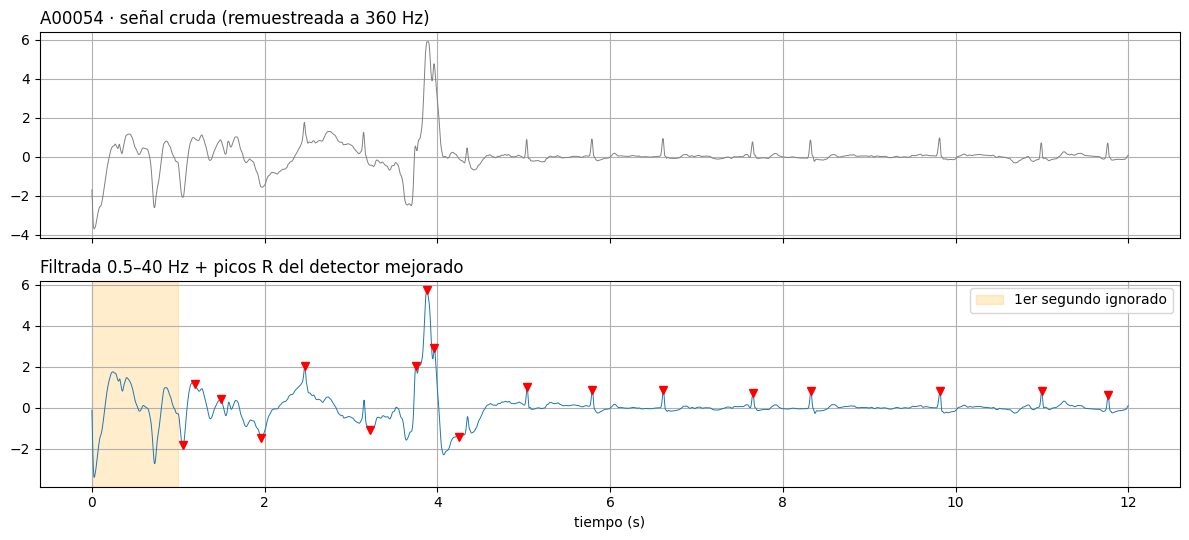

In [12]:
ejemplo = "A00054" if "A00054" in rutas else etiquetas.registro.iloc[0]
x, fs = leer_cinc(rutas[ejemplo])
limpia, r = preparar_senal(x, fs)
x360 = remuestrear(x, fs, FS)
n = min(len(x360), 12 * FS)
t = np.arange(n) / FS
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
ax[0].plot(t, x360[:n], lw=0.7, color="gray"); ax[0].set_title(f"{ejemplo} · señal cruda (remuestreada a 360 Hz)", loc="left")
ax[1].plot(t, limpia[:n], lw=0.7)
rr_ = r[r < n]
ax[1].plot(rr_ / FS, limpia[rr_], "rv", ms=6)
ax[1].axvspan(0, IGNORAR_INICIO_S, color="orange", alpha=0.2, label="1er segundo ignorado")
ax[1].set_title("Filtrada 0.5–40 Hz + picos R del detector mejorado", loc="left"); ax[1].legend(loc="upper right")
ax[1].set_xlabel("tiempo (s)")
plt.tight_layout(); plt.show()

## D.4 ¿Las dos bases se parecen? (riesgo de aprendizaje por atajo)

Si las medidas de una misma clase (por ejemplo, ritmo normal) fueran muy distintas entre CinC y MIT-BIH AF, el modelo podría aprender a reconocer la base en lugar del ritmo. Entonces comparamos las clases que existen en las dos (N y A).

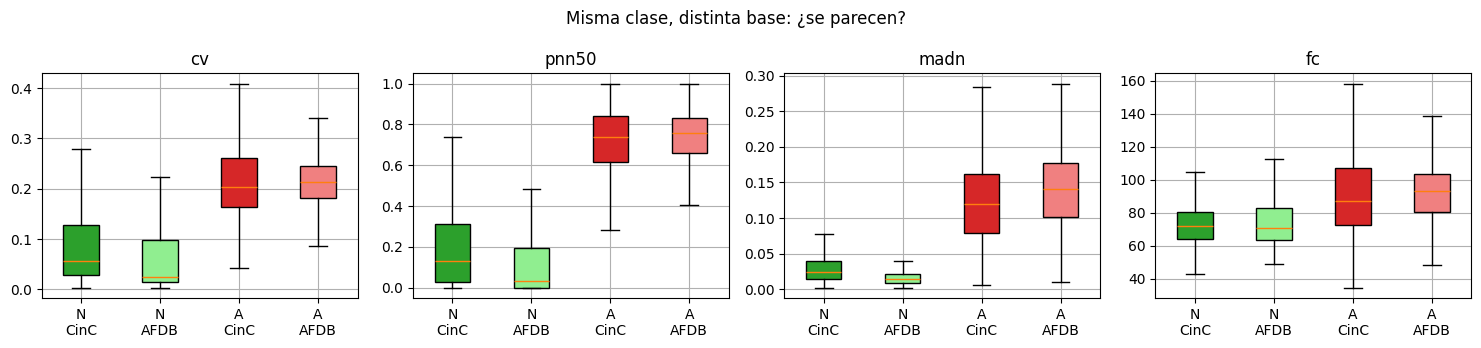

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
for eje, col in zip(ax, ["cv", "pnn50", "madn", "fc"]):
    datos, nombres = [], []
    for et in ["N", "A"]:
        for base in ["CinC2017", "MIT-BIH AF"]:
            datos.append(tabla[(tabla.base == base) & (tabla.etiqueta == et)][col].dropna())
            nombres.append(f"{et}\n{'CinC' if base == 'CinC2017' else 'AFDB'}")
    cajas = eje.boxplot(datos, showfliers=False, patch_artist=True)
    for caja, color in zip(cajas["boxes"], ["tab:green", "lightgreen", "tab:red", "lightcoral"]):
        caja.set_facecolor(color)
    eje.set_xticks(range(1, 5)); eje.set_xticklabels(nombres); eje.set_title(col)
plt.suptitle("Misma clase, distinta base: ¿se parecen?")
plt.tight_layout(); plt.show()


## D.5 Guardar

In [14]:
archivo = SALIDA / "medidas_ritmo.csv"
tabla.to_csv(archivo, index=False)
config = {"FS": FS, "FILTRO_HZ": FILTRO_HZ, "IGNORAR_INICIO_S": IGNORAR_INICIO_S, "VENTANA_S": VENTANA_S,
          "RR_MIN": RR_MIN, "RR_MAX": RR_MAX, "MIN_LATIDOS": MIN_LATIDOS, "PUREZA_MIN": PUREZA_MIN,
          "MAPEO_AFDB": MAPEO_AFDB, "MEDIDAS": MEDIDAS}
(SALIDA / "config_preparacion.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
print("Guardado:", archivo, f"({len(tabla)} filas)")
print("Guardado:", SALIDA / "config_preparacion.json")

Guardado: /kaggle/working/datos/medidas_ritmo.csv (36196 filas)
Guardado: /kaggle/working/datos/config_preparacion.json


---
# Resumen de este notebook 

| Paso | Tipo | Qué se hizo |
|---|---|---|
| Remuestreo a 360 Hz | Transformar | Las dos bases quedan en la misma frecuencia que el Arduino |
| Filtro causal 0.5–40 Hz | Limpiar | Quita la deriva de línea base y el ruido de alta frecuencia |
| Ignorar el primer segundo | Limpiar | Elimina el transitorio de arranque del filtro |
| Detector R mejorado | Limpiar | Umbral inicial robusto y recuperación tras artefactos |
| R–R fuera de 0.25–2.5 s | Limpiar | Se descartan como errores de detección |
| Ventanas de 30 s con pureza ≥ 90 % | Transformar | Etiquetas claras; las ventanas mezcladas se descartan |
| Mapeo de ritmos de MIT-BIH AF | Transformar | AFIB → A, N → N, AFL y J → O |
| 9 medidas relativas por ventana | Transformar + normalizar (por señal) | No dependen de la amplitud del aparato |
| Vacíos (pocos latidos) | Limpiar | Se marcan como vacíos; se rellenan en el notebook 04 solo con datos de entrenamiento |